# AgriStress-500 Plant→Plant Pipeline

Download the dataset -> sample cropped plant instances from one cluster -> generate embeddings via the PAI embedding API -> run Plant-to-Plant evaluation, using the `precisionai.agriemb` package that wires the three sibling projects together:

- [Precision AI Embeddings](https://embeddings.precision.ai/) - hosted image embedding API
- [`agrieval`](https://github.com/Precision-AI-Inc/agrieval) - embedding evaluation
- [`agristress-utils`](https://github.com/Precision-AI-Inc/agristress-utils) - dataset download and sampling

Plant→Plant measures how well cropped plant instance embeddings cluster by crop/weed class label. Class diversity depends on the chosen cluster — most L2 clusters contain a single dominant plant label, some contain several. This notebook defaults to cluster `G2`, which has three distinct labels (two weeds, one crop) for a more interesting demo.

**Setup** (from the repo root, before starting Jupyter):

```bash
pip install -e ".[notebook]"
cp .env.example .env   # fill in PAI_EMBEDDINGS_BASE_URL and PAI_EMBEDDINGS_API_KEY
```

Run all cells top-to-bottom. See the root `README.md` and the standalone `examples/01_download_dataset.py` plus `examples/plant2plant/01_sample_cluster_instances.py`-`03_run_eval.py` (or the bundled `04_end_to_end.py`) scripts for the non-notebook version.

In [ ]:
from IPython.display import display
from PIL import Image

from precisionai.agriemb import build_client, download, embed_images, run_p2p_evaluation, sample_cluster_instances
from precisionai.agriemb.config import DEFAULT_DATASET_DIR, DEFAULT_MODEL, DEFAULT_REPO_ID
from precisionai.agrieval.emb import plot_cosine_similarity, plot_knn_confusion, plot_tsne, print_result
from precisionai.agristress.utils import AgriStressDataset, normalize_embeddings, validate_embeddings

SEED = 0
NUM_SAMPLES = 6
MAX_INSTANCES_PER_IMAGE = 3

## 1. Download the dataset

In [ ]:
dataset_dir = download(DEFAULT_DATASET_DIR, repo_id=DEFAULT_REPO_ID)
dataset = AgriStressDataset(dataset_dir)
clusters = dataset.list_clusters()

print(f"Downloaded to {dataset_dir}")
print(f"Clusters : {len(clusters)}")
print(f"Images   : {len(dataset.list_image_ids())}")

## 2. Sample instance crops

Picks a cluster, draws `NUM_SAMPLES` parent images from it, and collects up to `MAX_INSTANCES_PER_IMAGE` cropped plant instances per parent. Pass `cluster=None` for a random cluster, or any id from `clusters` above.

In [3]:
cluster, images, instances = sample_cluster_instances(
    dataset,
    cluster="G2",
    num_samples=NUM_SAMPLES,
    max_instances_per_image=MAX_INSTANCES_PER_IMAGE,
    seed=SEED,
)
paths = dataset.resolve_paths(instances)

print(f"Cluster {cluster}: sampled {len(instances)} instance crops from {len(images)} images")

Cluster G2: sampled 18 instance crops from 6 images


### Preview the sampled instance crops

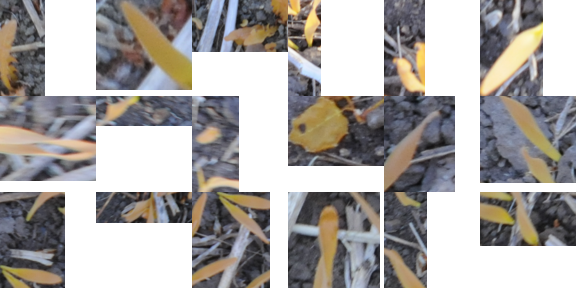

instances/G2/pai-EKLuYTwy-7.png
instances/G2/pai-EKLuYTwy-11.png
instances/G2/pai-EKLuYTwy-1.png
instances/G2/pai-mcirOPdn-5.png
instances/G2/pai-mcirOPdn-9.png
instances/G2/pai-mcirOPdn-8.png
instances/G2/pai-z8E4D9sS-13.png
instances/G2/pai-z8E4D9sS-15.png
instances/G2/pai-z8E4D9sS-16.png
instances/G2/pai-6BNyiFM0-10.png
instances/G2/pai-6BNyiFM0-8.png
instances/G2/pai-6BNyiFM0-6.png
instances/G2/pai-8XjgpdC6-7.png
instances/G2/pai-8XjgpdC6-9.png
instances/G2/pai-8XjgpdC6-3.png
instances/G2/pai-2a80gAHU-5.png
instances/G2/pai-2a80gAHU-3.png
instances/G2/pai-2a80gAHU-2.png


In [4]:
thumb_size = 96
cols = 6
rows = (len(instances) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, instance_id in enumerate(instances):
    thumb = Image.open(paths[instance_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

display(sheet)
print("\n".join(instances))

## 3. Generate embeddings via the PAI embedding API

Each sampled instance crop is base64-encoded as a `data:` URI and sent to the OpenAI-compatible PAI embedding API (https://embeddings.precision.ai/), then L2-normalized and validated.

In [5]:
client = build_client()
raw_embeddings = embed_images(client, paths, model=DEFAULT_MODEL)

embeddings = normalize_embeddings(raw_embeddings)
validate_embeddings(embeddings)

print(f"Generated {len(embeddings)} L2-normalized embeddings (dim={len(next(iter(embeddings.values())))})")

Generated 18 L2-normalized embeddings (dim=384)


## 4. Run Plant-to-Plant evaluation

`run_p2p_evaluation` assembles the instance-crop class labels from `plant2plant.json` (via `AgriStressDataset.build_p2p_payload`) and evaluates them with `agrieval`'s `run_plant2plant_eval` for graded nDCG and per-class separation metrics.

In [6]:
result = run_p2p_evaluation(dataset, embeddings, k_values=[5, 10])
print_result(result)

n_items      : 18
embedding_dim: 384
classes      : ['Crop | Barley', 'Weed | Broadleaf', 'Weed | Morning Glory']
k_values     : [5, 10]

── global_metrics ──────────────────────────────────────────────────────
  pairwise cosine    : mean=0.7676  std=0.1464  (p05=0.4328  p50=0.7869  p95=0.9360)
  centroid cosine    : mean=0.8835  std=0.0963  norm=0.8835
  intra/inter gap    : 0.0480  (intra=0.7823  inter=0.7343)
  effective_rank     : 5.60  (ratio=0.0146  dim=384)
  uniformity         : -0.7883
  alignment          : 0.4353

  hubness@5         : mean=5.0000  std=3.1798  p95=10.0000
  hubness@10        : mean=10.0000  std=5.4160  p95=17.0000
  knn_radius@5         : mean=0.8414  std=0.1066  p05=0.6603  p95=0.9311
  knn_radius@10        : mean=0.7846  std=0.1135  p05=0.5903  p95=0.8705
  mean_top_k_sim@5         : mean=0.8626  std=0.0967  p05=0.6908  p95=0.9419
  mean_top_k_sim@10        : mean=0.8373  std=0.1029  p05=0.6557  p95=0.9187
  outlier_score@5         : mean=0.1374  std=0.096

## 5. Visualize (optional)

Requires `precisionai-agrieval[analysis]` (already included in the `notebook` extra). `output_path=None` renders the interactive Plotly figure inline instead of saving an HTML file.

In [7]:
plot_cosine_similarity(embeddings, result, output_path=None)

In [8]:
plot_tsne(embeddings, result, output_path=None, dimensions=2)

  t-SNE 2D — fitting 18 samples (perplexity=6, iter=1000)...


In [9]:
plot_knn_confusion(result, k=5, output_path=None)